**Activity 6 — Breast Cancer Dataset Exploration**

This activity follows the Iris-style dataset exploration requested in the lab, then performs missing-value handling, class-balance checking, outlier detection, transformation, scaling, PCA, and two-classifier comparison.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

print("data.keys():", cancer.keys())
print("target_names:", cancer.target_names)

n_samples, n_features = cancer.data.shape
print("Number of samples:", n_samples)
print("Number of features:", n_features)
print("feature_names:", cancer.feature_names)
print("data.data shape:", cancer.data.shape)
print("data.target shape:", cancer.target.shape)

data.keys(): dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
target_names: ['malignant' 'benign']
Number of samples: 569
Number of features: 30
feature_names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
data.data shape: (569, 30)
data.target shape: (569,)


In [2]:
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df["target"] = cancer.target

print("Missing values before insertion:", df.isna().sum().sum())

rng = np.random.default_rng(7)
missing_rows = rng.choice(df.index, size=5, replace=False)
df.loc[missing_rows, "mean radius"] = np.nan

print("Rows changed:", missing_rows.tolist())
print("Missing mean-radius values:", df["mean radius"].isna().sum())

Missing values before insertion: 0
Rows changed: [353, 387, 533, 329, 509]
Missing mean-radius values: 5


In [3]:
radius_median = df["mean radius"].median()
df["mean radius"] = df["mean radius"].fillna(radius_median)

print("Median used:", radius_median)
print("Remaining missing mean-radius values:", df["mean radius"].isna().sum())

Median used: 13.29
Remaining missing mean-radius values: 0


In [4]:
class_counts = df["target"].value_counts().sort_index()
print("Class counts:")
print(class_counts)
print("Class labels:", dict(enumerate(cancer.target_names)))

imbalance_ratio = class_counts.max() / class_counts.min()
print("Largest/smallest class ratio:", round(imbalance_ratio, 3))

if imbalance_ratio > 1.5:
    print("The classes show a noticeable imbalance.")
else:
    print("The classes are relatively close in size.")

Class counts:
target
0    212
1    357
Name: count, dtype: int64
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}
Largest/smallest class ratio: 1.684
The classes show a noticeable imbalance.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (455, 30)
Scaled testing shape: (114, 30)


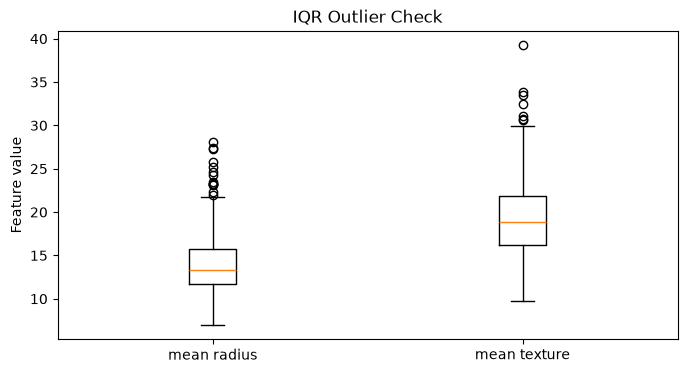

mean radius: 14 IQR outliers
mean texture: 7 IQR outliers


In [6]:
feature_a = "mean radius"
feature_b = "mean texture"

plt.figure(figsize=(8, 4))
plt.boxplot(
    [df[feature_a], df[feature_b]],
    tick_labels=[feature_a, feature_b]
)
plt.ylabel("Feature value")
plt.title("IQR Outlier Check")
plt.show()

for feature in [feature_a, feature_b]:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[feature] < low) | (df[feature] > high)).sum()
    print(f"{feature}: {count} IQR outliers")

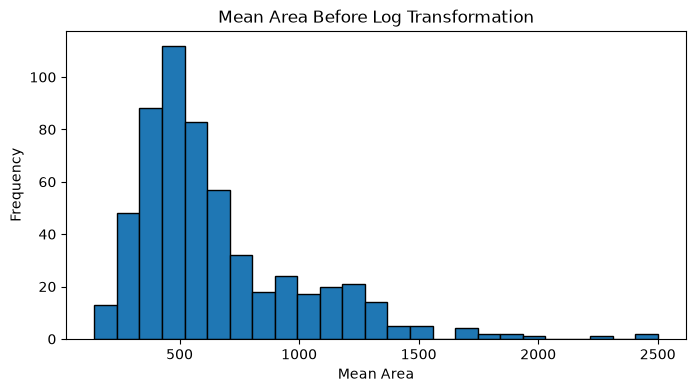

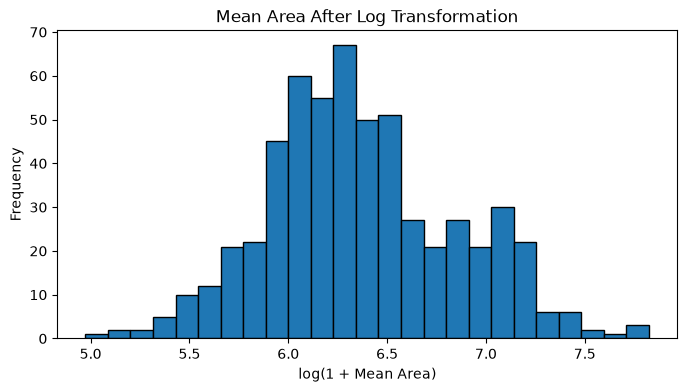

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(df["mean area"], bins=25, edgecolor="black")
plt.xlabel("Mean Area")
plt.ylabel("Frequency")
plt.title("Mean Area Before Log Transformation")
plt.show()

df["log_mean_area"] = np.log1p(df["mean area"])

plt.figure(figsize=(8, 4))
plt.hist(df["log_mean_area"], bins=25, edgecolor="black")
plt.xlabel("log(1 + Mean Area)")
plt.ylabel("Frequency")
plt.title("Mean Area After Log Transformation")
plt.show()

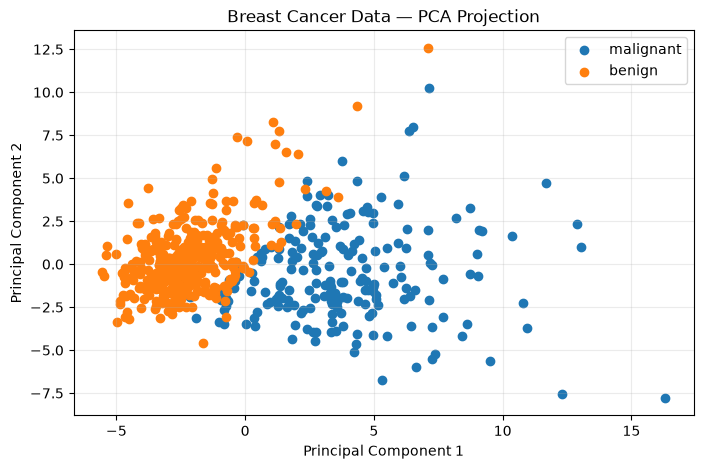

Explained variance ratio: [0.44253532 0.18969665]
Total variance in 2 components: 0.6322319721732708


In [8]:
from sklearn.decomposition import PCA

# Fit PCA on the complete scaled feature matrix for visualization.
X_scaled_all = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_all)

plt.figure(figsize=(8, 5))
for class_id, class_name in enumerate(cancer.target_names):
    mask = y.to_numpy() == class_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=class_name)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Breast Cancer Data — PCA Projection")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance in 2 components:", pca.explained_variance_ratio_.sum())

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

svm = SVC(kernel="rbf", class_weight="balanced", random_state=42)
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

print("KNN accuracy:", accuracy_score(y_test, knn_pred))
print("SVM accuracy:", accuracy_score(y_test, svm_pred))

print("\nKNN confusion matrix:")
print(confusion_matrix(y_test, knn_pred))
print("\nSVM confusion matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nKNN classification report:")
print(classification_report(y_test, knn_pred, target_names=cancer.target_names))
print("\nSVM classification report:")
print(classification_report(y_test, svm_pred, target_names=cancer.target_names))

KNN accuracy: 0.956140350877193
SVM accuracy: 0.9649122807017544

KNN confusion matrix:
[[39  3]
 [ 2 70]]

SVM confusion matrix:
[[41  1]
 [ 3 69]]

KNN classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


SVM classification report:
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



In [10]:
print(
    "Scaling is a key preprocessing step here because KNN uses distances "
    "and SVM is sensitive to feature scale. Outlier handling, PCA, and "
    "imbalance correction can also affect results, so their impact should "
    "be measured by controlled comparisons rather than assumed."
)

Scaling is a key preprocessing step here because KNN uses distances and SVM is sensitive to feature scale. Outlier handling, PCA, and imbalance correction can also affect results, so their impact should be measured by controlled comparisons rather than assumed.
